In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = "../data/Telco-Customer-Churn.csv"

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Missing values per column (NaN):")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("(empty above means no true NaNs)\n")

print("Fully duplicated rows:", df.duplicated().sum())
print("Unique customerIDs:", df["customerID"].nunique(), "of", len(df))

Missing values per column (NaN):
Series([], dtype: int64)
(empty above means no true NaNs)

Fully duplicated rows: 0
Unique customerIDs: 7043 of 7043


In [5]:
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges entries:", blank_mask.sum())

df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


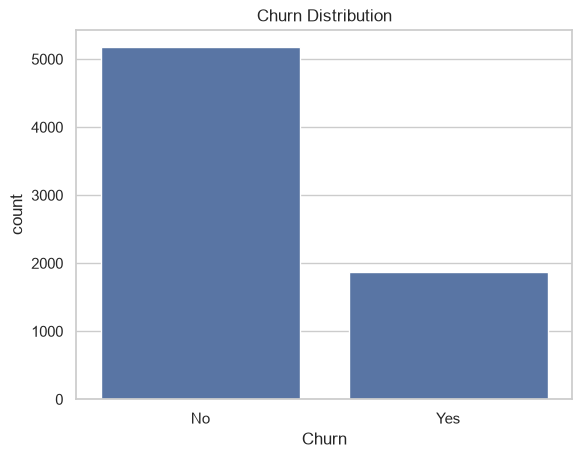

In [6]:
counts = df["Churn"].value_counts()
percent = df["Churn"].value_counts(normalize=True).mul(100).round(2)

print(pd.DataFrame({"count": counts, "percent": percent}))

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

In [7]:
print("Numerical summary:")
display(df.describe())

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(exclude="number").columns:
    if col not in ["customerID", "TotalCharges"]:
        print(f"{col:20s} -> {df[col].unique().tolist()}")

Numerical summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Unique values in categorical columns:
gender               -> ['Female', 'Male']
Partner              -> ['Yes', 'No']
Dependents           -> ['No', 'Yes']
PhoneService         -> ['No', 'Yes']
MultipleLines        -> ['No phone service', 'No', 'Yes']
InternetService      -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity       -> ['No', 'Yes', 'No internet service']
OnlineBackup         -> ['Yes', 'No', 'No internet service']
DeviceProtection     -> ['No', 'Yes', 'No internet service']
TechSupport          -> ['No', 'Yes', 'No internet service']
StreamingTV          -> ['No', 'Yes', 'No internet service']
StreamingMovies      -> ['No', 'Yes', 'No internet service']
Contract             -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling     -> ['Yes', 'No']
PaymentMethod        -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn                -> ['No', 'Yes']


In [8]:
import sys
sys.path.append("..")   # lets the notebook import from src/

from src.preprocessing import load_data, clean_data

raw = load_data(DATA_PATH)
df_clean = clean_data(raw)
print("Cleaning finished without errors.")

Cleaning finished without errors.


In [9]:
print("Shape before:", raw.shape, "-> after:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Churn counts:", df_clean["Churn"].value_counts().to_dict())
print("customerID still present:", "customerID" in df_clean.columns)
print("Duplicate feature rows (after dropping ID):", df_clean.duplicated().sum())

print("\nThe 11 originally-blank rows, now cleaned:")
blank_rows = raw["TotalCharges"].str.strip() == ""
display(df_clean.loc[blank_rows, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

df_clean.describe()

Shape before: (7043, 21) -> after: (7043, 20)
Total missing values: 0
TotalCharges dtype: float64
Churn counts: {0: 5174, 1: 1869}
customerID still present: False
Duplicate feature rows (after dropping ID): 22

The 11 originally-blank rows, now cleaned:


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,0
753,0,20.25,0.0,0
936,0,80.85,0.0,0
1082,0,25.75,0.0,0
1340,0,56.05,0.0,0
3331,0,19.85,0.0,0
3826,0,25.35,0.0,0
4380,0,20.00,0.0,0
5218,0,19.70,0.0,0
6670,0,73.35,0.0,0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000
